## Part II: Embedding Variants & Ablation (LSTM)
**Question:** does the input embedding matter, and is it trainability or extra data that helps?

| Setting | Embedding table | Source of the vectors |
|---|---|---|
| **A. Random** | trainable | random init (reused from Part 1: same CFG, seed, data, procedure) |
| **B. Own (frozen)** | fixed | Skip-gram (SGNS) trained by me on the *Little Women* **train split only** |
| **C. GloVe (frozen)** | fixed | public GloVe 6B-100d (Wikipedia + Gigaword, ~6B tokens) |

Everything except the embedding table is identical: LSTM architecture, dim 100, data, CFG, seed, optimiser, early stopping. Because the same seed is set before building each model, the **LSTM and output-layer weights start identical** in all three runs; only the embedding table differs.


In [1]:
# 1. Mount Drive + paths
import os, sys
try:                                            # running in Google Colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DSA4213_A1'
except ImportError:                             # running locally (VS Code / Jupyter)
    BASE = os.path.abspath('DSA4213_A1')
print('Working folder:', BASE)
OUT  = f'{BASE}/outputs'
sys.path.append(BASE)
assert os.path.exists(f'{BASE}/lm_utils.py'), 'Run the Part I notebook first (it creates lm_utils.py)'
assert os.path.exists(f'{OUT}/lstm_random.pt'), 'Part I LSTM not found'

Working folder: /Users/kellytan/DSA4213-assignment1report/DSA4213_A1


Imports, data, config

In [ ]:
import json, math, time, pickle, re, zipfile, urllib.request
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import importlib, lm_utils; importlib.reload(lm_utils)
from lm_utils import *

SEED = 42; set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
HARDWARE = torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'
print('Device:', device, '|', HARDWARE)

prep = pickle.load(open(f'{OUT}/data_prep.pkl', 'rb'))
itos, stoi = prep['itos'], prep['stoi']
train_ids, val_ids, test_ids = prep['train_ids'], prep['val_ids'], prep['test_ids']
V = len(itos)

CFG = dict(seq_len=64, emb_dim=100, hidden=256, layers=2, dropout=0.3,
           d_model=256, nhead=4, ff=512,
           lr=1e-3, batch_size=32, max_epochs=150, patience=3)        # same as Part I
EMB_DIM = CFG['emb_dim']                                             # 100 = matches GloVe-100d

Xtr, Ytr = make_lm_tensors(train_ids, CFG['seq_len'])
Xva, Yva = make_lm_tensors(val_ids,   CFG['seq_len'])
Xte, Yte = make_lm_tensors(test_ids,  CFG['seq_len'])

P1 = json.load(open(f'{OUT}/part1_results.json'))
RES_PATH = f'{OUT}/part2_results.json'
RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def save_results(): json.dump(RESULTS, open(RES_PATH, 'w'), indent=1)
print(f'Vocab {V:,} | Part I LSTM test ppl {P1["lstm"]["test_ppl"]:.1f} | already done: {list(RESULTS)}')

Device: cuda | Tesla T4
Vocab 5,641 | Part I LSTM test ppl 106.2 | already done: ['sgns_cost', 'own_frozen', 'glove_frozen']


## Train my own embeddings: Skip-gram with negative sampling (SGNS)

Written in plain PyTorch (no extra library), trained on the **train split only** so val/test never leak in.
- Predict context words within a window of 5 around each centre word; dynamic window size; frequent-word subsampling (t = 1e-4).
- 5 negative samples per positive pair, drawn from the unigram distribution^0.75 (standard word2vec choices).
- The time spent here is reported **separately** from language-model training, as the brief requires.

In [ ]:
def sgns_pairs(ids, window, keep_prob, rng):
    # Skip-gram (center, context) pairs for one epoch.
    # 1) subsample frequent words
    # 2) dynamic window: each centre uses a random size b in [1, window].
    ids = np.asarray(ids)
    ids = ids[rng.random(len(ids)) < keep_prob[ids]]
    b = rng.integers(1, window + 1, size=len(ids))
    centres, contexts = [], []
    for o in range(1, window + 1):
        m = b[:-o] >= o                                   # centre i looks right by o
        centres.append(ids[:-o][m]); contexts.append(ids[o:][m])
        m = b[o:] >= o                                    # centre i looks left by o
        centres.append(ids[o:][m]); contexts.append(ids[:-o][m])
    return np.concatenate(centres), np.concatenate(contexts)


def glove_lookup(word, glove):
    # Exact match, else compose contractions the way GloVe's tokenizer splits them
    # (don't -> do + n't, i'm -> i + 'm). Returns (vector or None, how)
    if word in glove:
        return glove[word], 'exact'
    if "'" in word:
        parts = [word[:-3], "n't"] if word.endswith("n't") else [word.split("'")[0], "'" + word.split("'")[1]]
        vecs = [glove[p] for p in parts if p in glove]
        if len(vecs) == len(parts):
            return np.mean(vecs, axis=0), 'composed'
    return None, 'missing'


Train SGNS embeddings

In [ ]:
SGNS = dict(dim=EMB_DIM, window=5, neg=5, epochs=30, batch=1024, lr=2e-3, subsample_t=1e-4)
SGNS_PATH = f'{OUT}/emb_sgns_30ep.npy'

class SGNS_Model(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d); self.out = nn.Embedding(V, d)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d); nn.init.zeros_(self.out.weight)
    def forward(self, c, x, negs):
        u = self.inp(c)                                                   # (B, d)
        pos = F.logsigmoid((u * self.out(x)).sum(-1))                    # (B,)
        neg = F.logsigmoid(-torch.bmm(self.out(negs), u.unsqueeze(-1)).squeeze(-1)).sum(-1)
        return -(pos + neg).mean()

if os.path.exists(SGNS_PATH):
    E_sgns = np.load(SGNS_PATH); RESULTS.setdefault('sgns_cost', {})
    print('Loaded cached SGNS embeddings', E_sgns.shape, '| training time recorded:', RESULTS['sgns_cost'])
else:
    set_seed(SEED); rng = np.random.default_rng(SEED)
    counts = np.bincount(np.array(train_ids), minlength=V).astype(float)
    freq = counts / counts.sum()
    keep_prob = np.minimum(1.0, np.sqrt(SGNS['subsample_t'] / np.maximum(freq, 1e-12)) + SGNS['subsample_t'] / np.maximum(freq, 1e-12))
    keep_prob[PAD_ID] = 0.0
    noise = torch.tensor(counts ** 0.75); noise[PAD_ID] = 0; noise = (noise / noise.sum()).float().to(device)

    sg = SGNS_Model(V, SGNS['dim']).to(device)
    opt = torch.optim.Adam(sg.parameters(), lr=SGNS['lr'])
    sync(device); t0 = time.perf_counter(); sgns_losses = []
    for ep in range(SGNS['epochs']):
        c, x = sgns_pairs(train_ids, SGNS['window'], keep_prob, rng)
        perm = rng.permutation(len(c)); c, x = torch.tensor(c[perm]), torch.tensor(x[perm])
        tot = 0.0
        for i in range(0, len(c), SGNS['batch']):
            cb, xb = c[i:i+SGNS['batch']].to(device), x[i:i+SGNS['batch']].to(device)
            negs = torch.multinomial(noise, len(cb) * SGNS['neg'], replacement=True).view(len(cb), SGNS['neg'])
            loss = sg(cb, xb, negs)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(cb)
        sgns_losses.append(tot / len(c))
        print(f'  SGNS epoch {ep+1}: {len(c):,} pairs | loss {sgns_losses[-1]:.3f}')
    sync(device); sgns_time = time.perf_counter() - t0
    E_sgns = sg.inp.weight.detach().cpu().numpy(); E_sgns[PAD_ID] = 0
    np.save(SGNS_PATH, E_sgns)
    RESULTS['sgns_cost'] = dict(train_time_s=sgns_time, epochs=SGNS['epochs'], losses=sgns_losses,
                                settings=SGNS, hardware=HARDWARE); save_results()
    print(f'SGNS done in {sgns_time:.1f}s')

Loaded cached SGNS embeddings (5641, 100) | training time recorded: {'train_time_s': 26.672893139000053, 'epochs': 30, 'losses': [2.90518685300935, 2.637272072808717, 2.621805168114793, 2.597434369572597, 2.5618360145077577, 2.5117850506749795, 2.4478142133101946, 2.377877768663417, 2.31326325845049, 2.2544844587227684, 2.208498698302923, 2.167645908375014, 2.133541164673128, 2.1050285529548884, 2.077008337823721, 2.0581460228863566, 2.038729671972505, 2.024185189797161, 2.0107661909445103, 1.9992553755761768, 1.9863570007760973, 1.977252746977142, 1.9716072861875025, 1.9589201206114621, 1.9523202455341357, 1.9417083610545116, 1.9437381617877831, 1.9324633325791305, 1.9296759523721707, 1.9204879985045615], 'settings': {'dim': 100, 'window': 5, 'neg': 5, 'epochs': 30, 'batch': 1024, 'lr': 0.002, 'subsample_t': 0.0001}, 'hardware': 'Tesla T4'}


## public GloVe 6B-100d
Downloaded once (~860 MB zip, from the Stanford NLP mirror on HuggingFace), only the 100-d file is read, and the final 5,641 × 100 matrix is cached to Drive so later runs skip the download.

**Vocabulary coverage + missing words (document these in the report):**
1. *exact* : word found in GloVe as-is
2. *composed* : contractions are split the way GloVe's tokenizer splits them (`don't` → `do` + `n't`) and the part vectors are averaged
3. *missing* : random vector ~ N(0, σ²) with σ = std of the GloVe vectors used (same scale), fixed seed
- `<pad>` = zeros; `<unk>` = mean of all matched GloVe vectors

In [ ]:
# 5. Build the GloVe embedding matrix
GLOVE_PATH = f'{OUT}/emb_glove.npy'
COV_PATH = f'{OUT}/glove_coverage.json'
if os.path.exists(GLOVE_PATH):
    E_glove = np.load(GLOVE_PATH); coverage = json.load(open(COV_PATH))
    print('Loaded cached GloVe matrix', E_glove.shape)
else:
    zip_path = os.path.join('/content' if os.path.isdir('/content') else BASE, 'glove.6B.zip')  # Colab: temp disk
    if not os.path.exists(zip_path):
        for url in ['https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip',
                    'https://nlp.stanford.edu/data/glove.6B.zip']:
            try:
                print('Downloading', url, '(~860 MB, 1-3 min)...'); urllib.request.urlretrieve(url, zip_path); break
            except Exception as e:
                print('  failed:', e)
    glove = {}
    with zipfile.ZipFile(zip_path) as z, z.open('glove.6B.100d.txt') as f:
        for line in f:
            parts = line.decode('utf-8').rstrip().split(' ')
            glove[parts[0]] = np.asarray(parts[1:], dtype=np.float32)
    print(f'GloVe words loaded: {len(glove):,}')

    E_glove = np.zeros((V, EMB_DIM), dtype=np.float32); how = {}
    for i, w in enumerate(itos):
        if i in (PAD_ID, UNK_ID): continue
        vec, how[w] = glove_lookup(w, glove)
        if vec is not None: E_glove[i] = vec
    found = [i for i, w in enumerate(itos) if how.get(w) in ('exact', 'composed')]
    sigma = float(E_glove[found].std())
    rng = np.random.default_rng(SEED)
    missing_words = [w for w in itos if how.get(w) == 'missing']
    for w in missing_words:
        E_glove[stoi[w]] = rng.normal(0, sigma, EMB_DIM)
    E_glove[UNK_ID] = E_glove[found].mean(0)

    tok_counts = Counter(train_ids)
    n_tok = sum(c for i, c in tok_counts.items() if i not in (PAD_ID, UNK_ID))
    coverage = {k: sum(1 for w in how if how[w] == k) for k in ('exact', 'composed', 'missing')}
    coverage['vocab_coverage_pct'] = 100 * (coverage['exact'] + coverage['composed']) / len(how)
    coverage['token_coverage_pct'] = 100 * sum(tok_counts[stoi[w]] for w in how if how[w] != 'missing') / n_tok
    coverage['missing_examples'] = sorted(missing_words, key=lambda w: -tok_counts[stoi[w]])[:25]
    coverage['random_init_sigma'] = sigma
    json.dump(coverage, open(COV_PATH, 'w'), indent=1)
    np.save(GLOVE_PATH, E_glove)
    del glove

print(f"Vocab coverage: {coverage['vocab_coverage_pct']:.1f}%  (exact {coverage['exact']:,} + composed {coverage['composed']:,}; missing {coverage['missing']:,})")
print(f"Train-token coverage: {coverage['token_coverage_pct']:.1f}%")
print('Most frequent missing words:', coverage['missing_examples'])

Loaded cached GloVe matrix (5641, 100)
Vocab coverage: 98.7%  (exact 5,454 + composed 113; missing 72)
Train-token coverage: 99.9%
Most frequent missing words: ['bhaer', 'plumfield', "bhaer's", 'capitally', 'housewifely', 'bethy', 'laurences', 'rumpling', 'wheedlesome', 'basely', 'confidingly', 'consolingly', 'crossly', 'demijohn', 'dranpa', 'imploringly', 'inkstand', 'lovelornity', 'mantlepiece', 'parpar', 'phine', 'pleasanter', 'scarum', 'workbasket', 'aisy']


In [ ]:
# 6. Sanity check: do the vectors make sense (nearest neighbours by cosine similarity)
def neighbours(E, word, k=6):
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-8)
    sims = En @ En[stoi[word]]
    sims[[PAD_ID, UNK_ID, stoi[word]]] = -1
    return [itos[i] for i in np.argsort(-sims)[:k]]

PROBE = ['jo', 'laurie', 'christmas', 'happy', 'mother', 'said']
nn_rows = [{'word': w, 'own SGNS (Little Women)': ', '.join(neighbours(E_sgns, w)),
            'GloVe (Wikipedia/news)': ', '.join(neighbours(E_glove, w))} for w in PROBE if w in stoi]
nn_table = pd.DataFrame(nn_rows); nn_table.to_csv(f'{OUT}/table_part2_neighbours.csv', index=False)
pd.set_option('display.max_colwidth', 80); nn_table

,word,own SGNS (Little Women),GloVe (Wikipedia/news)
0,jo,"said, "", ,, ., amy, and","jo's, amy, ellen, mary, annie, fred"
1,laurie,"jo, ,, said, ., "", ?","laurie's, kate, ellen, peck, amy, parker"
2,christmas,"bloomed, regularly, merry, chrysanthemums, recesses, greeting","holiday, eve, holidays, wedding, day, birthday"
3,happy,"november, dear, home, comfortable, so, impulses","i'm, i'll, we'd, we'll, we're, feel"
4,mother,"father, "", you, ?, to, be","daughter, wife, grandmother, father, sister, mother's"
5,said,"jo, "", ., ,, laurie, amy","told, says, saying, added, asked, ,"


## Train the two frozen-embedding LSTMs
Same train_lm, same CFG, same seed. The embedding table is copied in and frozen (`requires_grad = False`); only the LSTM + output layer are trained from scratch. The assert at the end proof the table didn't change during training.

In [ ]:
# 7. Train -> test -> verify frozen -> save
P2_MODELS = {}
def train_frozen(name, E):
    set_seed(SEED)
    model = build_model('lstm', V, CFG, emb_weights=E, freeze_emb=True)
    E_before = model.emb.weight.detach().clone()
    total, trainable = count_params(model)
    print(f'{name}: {total:,} params total | {trainable:,} trainable (embedding {V*EMB_DIM:,} frozen)')
    hist = train_lm(model, Xtr, Ytr, Xva, Yva, device, lr=CFG['lr'], max_epochs=CFG['max_epochs'],
                    patience=CFG['patience'], batch_size=CFG['batch_size'], seed=SEED)
    assert torch.equal(model.emb.weight.detach().cpu(), E_before.cpu()), 'Embedding table changed!'
    test_ce = run_epoch(model, Xte, Yte, device)
    torch.save(model.state_dict(), f'{OUT}/lstm_{name}.pt')
    RESULTS[name] = dict(test_ce=test_ce, test_ppl=math.exp(test_ce), params=total, trainable=trainable,
                         train_time_s=hist['train_time_s'], best_epoch=hist['best_epoch'],
                         epochs_run=hist['epochs_run'], hardware=HARDWARE, history=hist)
    save_results(); P2_MODELS[name] = model
    print(f'-> TEST ppl {math.exp(test_ce):.1f} | best epoch {hist["best_epoch"]} | train {hist["train_time_s"]:.0f}s | embedding unchanged\n')
    return model

In [ ]:
train_frozen('own_frozen', E_sgns);

own_frozen: 2,906,765 params total | 2,342,665 trainable (embedding 564,100 frozen)
  epoch  1 | train 6.381 | val 5.847 (ppl  346.2) |   2.6s
  epoch  2 | train 6.052 | val 5.821 (ppl  337.4) |   1.2s
  epoch  3 | train 6.033 | val 5.815 (ppl  335.2) |   1.2s
  epoch  4 | train 5.996 | val 5.765 (ppl  319.0) |   1.2s
  epoch  5 | train 5.945 | val 5.721 (ppl  305.4) |   1.2s
  epoch  6 | train 5.906 | val 5.692 (ppl  296.6) |   1.2s
  epoch  7 | train 5.870 | val 5.643 (ppl  282.2) |   1.2s
  epoch  8 | train 5.807 | val 5.547 (ppl  256.6) |   1.2s
  epoch  9 | train 5.721 | val 5.460 (ppl  235.2) |   1.2s
  epoch 10 | train 5.653 | val 5.409 (ppl  223.5) |   1.2s
  epoch 11 | train 5.601 | val 5.363 (ppl  213.4) |   1.2s
  epoch 12 | train 5.552 | val 5.320 (ppl  204.5) |   1.2s
  epoch 13 | train 5.505 | val 5.278 (ppl  196.0) |   1.2s
  epoch 14 | train 5.460 | val 5.239 (ppl  188.5) |   1.2s
  epoch 15 | train 5.414 | val 5.204 (ppl  182.0) |   1.2s
  epoch 16 | train 5.373 | val 

In [ ]:
train_frozen('glove_frozen', E_glove);

glove_frozen: 2,906,765 params total | 2,342,665 trainable (embedding 564,100 frozen)
  epoch  1 | train 6.356 | val 5.840 (ppl  343.8) |   1.3s
  epoch  2 | train 6.055 | val 5.826 (ppl  338.9) |   1.3s
  epoch  3 | train 6.038 | val 5.817 (ppl  335.9) |   1.3s
  epoch  4 | train 5.978 | val 5.685 (ppl  294.4) |   1.3s
  epoch  5 | train 5.840 | val 5.551 (ppl  257.4) |   1.3s
  epoch  6 | train 5.744 | val 5.479 (ppl  239.5) |   1.3s
  epoch  7 | train 5.673 | val 5.407 (ppl  223.1) |   1.3s
  epoch  8 | train 5.600 | val 5.338 (ppl  208.2) |   1.3s
  epoch  9 | train 5.537 | val 5.278 (ppl  196.0) |   1.3s
  epoch 10 | train 5.473 | val 5.216 (ppl  184.2) |   1.3s
  epoch 11 | train 5.409 | val 5.159 (ppl  174.1) |   1.3s
  epoch 12 | train 5.352 | val 5.111 (ppl  165.9) |   1.3s
  epoch 13 | train 5.302 | val 5.064 (ppl  158.2) |   1.3s
  epoch 14 | train 5.253 | val 5.028 (ppl  152.6) |   1.3s
  epoch 15 | train 5.204 | val 4.984 (ppl  146.1) |   1.3s
  epoch 16 | train 5.160 | va

## Results

In [ ]:
# 8. Comparison table (setting A comes straight from Part 1)
A = P1['lstm']
SETTINGS = {'A. Random (trainable)': A, 'B. Own SGNS (frozen)': RESULTS['own_frozen'], 'C. GloVe (frozen)': RESULTS['glove_frozen']}
EMB_COST = {'A. Random (trainable)': 'none (learned during LM training)',
            'B. Own SGNS (frozen)': f"{RESULTS['sgns_cost'].get('train_time_s', float('nan')):.1f}s on {HARDWARE}, ~184k train tokens",
            'C. GloVe (frozen)': 'pretrained externally on ~6B tokens (not our compute)'}

def stability(h):
    v = np.array(h['val_loss'])
    return dict(val_up_epochs=int((np.diff(v) > 0).sum()),                     # how often val loss went UP
                gap_at_best=float(np.array(h['train_loss'])[h['best_epoch']-1] - v[h['best_epoch']-1]))

rows = []
for name, r in SETTINGS.items():
    s = stability(r['history'])
    rows.append({'Setting': name, 'Test PPL': round(r['test_ppl'], 1), 'Best val PPL': round(math.exp(min(r['history']['val_loss'])), 1),
                 'Epochs (best/run)': f"{r['best_epoch']}/{r['epochs_run']}",
                 'Epochs to val PPL < 120': next((i+1 for i, v in enumerate(r['history']['val_loss']) if math.exp(v) < 120), '-'),
                 'LM train time (s)': round(r['train_time_s'], 1),
                 'Trainable params': f"{r.get('trainable', r['params']):,}",
                 '# epochs val got worse': s['val_up_epochs'],
                 'Embedding cost (separate)': EMB_COST[name]})
table2 = pd.DataFrame(rows); table2.to_csv(f'{OUT}/table_part2.csv', index=False)
table2

,Setting,Test PPL,Best val PPL,Epochs (best/run),Epochs to val PPL < 120,LM train time (s),Trainable params,# epochs val got worse,Embedding cost (separate)
0,A. Random (trainable),106.2,88.3,43/46,15,57.2,"2,906,765",7,none (learned during LM training)
1,B. Own SGNS (frozen),128.5,107.1,65/68,40,84.6,"2,342,665",4,"26.7s on Tesla T4, ~184k train tokens"
2,C. GloVe (frozen),115.1,95.7,58/61,23,79.9,"2,342,665",4,pretrained externally on ~6B tokens (not our compute)


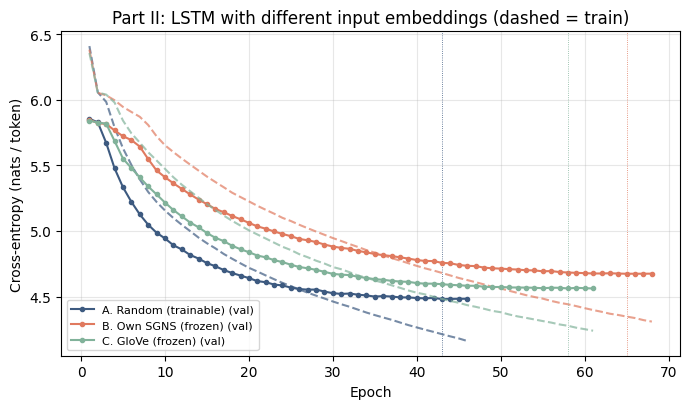

In [ ]:
# 9. Learning curves for the three embedding settings
fig, ax = plt.subplots(figsize=(7, 4.2))
cols = {'A. Random (trainable)': '#3D5A80', 'B. Own SGNS (frozen)': '#E07A5F', 'C. GloVe (frozen)': '#81B29A'}
for name, r in SETTINGS.items():
    h = r['history']; ep = range(1, len(h['val_loss']) + 1)
    ax.plot(ep, h['train_loss'], '--', color=cols[name], alpha=0.7)
    ax.plot(ep, h['val_loss'], '-o', ms=3, color=cols[name], label=f'{name} (val)')
    ax.axvline(h['best_epoch'], color=cols[name], lw=0.6, ls=':')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy (nats / token)')
ax.set_title('Part II: LSTM with different input embeddings (dashed = train)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_part2_loss.png', dpi=200); plt.show()

In [ ]:
# 10. Generated text: same prompts + decoding as Part 1
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;:\"]")
def encode(t): return [stoi.get(w, UNK_ID) for w in TOKEN_RE.findall(t.lower())]
PROMPTS = ["jo laughed and said", "it was a cold winter morning and", "christmas won't be christmas without"]
GEN = dict(n_tokens=40, temperature=0.8, top_k=40, seed=SEED)

def get_model(name):
    if name not in P2_MODELS:
        E = None if name == 'random' else (E_sgns if name == 'own_frozen' else E_glove)
        m = build_model('lstm', V, CFG, emb_weights=E, freeze_emb=E is not None)
        m.load_state_dict(torch.load(f'{OUT}/lstm_{name}.pt', map_location=device)); P2_MODELS[name] = m.to(device)
    return P2_MODELS[name]

gens = {}
for p in PROMPTS:
    print('=' * 100, f'\nPROMPT: {p}'); gens[p] = {}
    for name in ['random', 'own_frozen', 'glove_frozen']:
        out = generate_neural(get_model(name), encode(p), GEN['n_tokens'], device, GEN['temperature'], GEN['top_k'], CFG['seq_len'], GEN['seed'])
        gens[p][name] = detok([itos[i] for i in out]); print(f'\n[{name:12s}] {gens[p][name]}')
json.dump({'settings': GEN, 'generations': gens}, open(f'{OUT}/part2_generations.json', 'w'), indent=1)

PROMPT: jo laughed and said

[random      ] , as she had got a pair of the family and amy in the middle of his own. " i'm all, it's a nice thing? " " i, dear, " said amy, wondering that

[own_frozen  ] , " i won't know to the best. " " i can't go to a little man. " " i can have a nice? " asked jo, trying to soothe, and he had taken to

[glove_frozen] , " i won't know to know you. " " i can't see you. i had only more things to keep it at once, " cried jo, trying to soothe her out, saying to the
PROMPT: it was a cold winter morning and

[random      ] be busy, and you shall know you to see you, ma'am, and i can't want to try to go, if you were all? " " i didn't see how this is very kind to you

[own_frozen  ] be very, and no sure the best to see and mother, and he could do it. " " i love it is a thing? " " why, i do, sir, " began jo

[glove_frozen] be very, and you shall know we shall have done to your own, and then it. " " i can't have a nice thing? " " and, i suppose, you are so much y